# 02 - pvlib: how much PV does a Fresno rooftop make, and when?

[pvlib](https://pvlib-python.readthedocs.io) turns weather (sun +
temperature + wind) into PV power.

Things I want to find out:
1. How to get weather for Fresno (NREL NSRDB, or a fallback)
2. The basic chain: sun position -> irradiance on the panel -> cell temperature -> power
3. Does the easy `ModelChain` give the same answer as doing it by hand?
4. Tilt and direction: does facing west help, given CAISO prices peak in the evening?
5. Fixed vs single-axis tracking
6. How much does heat hurt the panels in summer?

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pvlib

import config

plt.rcParams["figure.dpi"] = 72
print("pvlib", pvlib.__version__)

pvlib 0.16.1


## 1. Weather

The real source is NREL's NSRDB, which pvlib can download if there's an
API key in `.env`. NREL was renamed (National Laboratory of the Rockies)
and the API moved to developer.nlr.gov; pvlib 0.16 already uses the new
address.

**When I ran this notebook I had no key and no access to NREL's
servers**, so it falls back to a *clear-sky* model (no clouds ever) plus a
made-up temperature curve. That's fine for learning the tool but it
overestimates PV. Re-run with a key to get real weather.

In [2]:
loc = pvlib.location.Location(config.LATITUDE, config.LONGITUDE, tz=config.TIMEZONE, altitude=100)
times = pd.date_range(f"{config.YEAR}-01-01", f"{config.YEAR + 1}-01-01", freq="h",
                      inclusive="left", tz=config.TIMEZONE)

weather = None
if config.NREL_API_KEY and config.NREL_EMAIL:
    try:
        weather, meta = pvlib.iotools.get_nsrdb_psm4_aggregated(
            config.LATITUDE, config.LONGITUDE, config.NREL_API_KEY, config.NREL_EMAIL,
            year=config.YEAR, time_step=60)
        weather_source = f"NSRDB {config.YEAR}"
        # NSRDB hourly data has been stamped at hh:30 in the past - check!
        print("first timestamps:", list(weather.index[:3]))
    except Exception as e:
        print("NSRDB download failed:", e)

if weather is None:
    weather_source = "clear-sky + made-up temperature (NOT real weather)"
    weather = loc.get_clearsky(times)   # ghi, dni, dhi
    doy = times.dayofyear.values
    hour = times.hour.values
    # Fresno-ish: ~8 C average in January, ~28 C in July, +/-7 C day/night swing
    weather["temp_air"] = 18 + 10 * np.cos(2 * np.pi * (doy - 200) / 365) + 7 * np.cos(2 * np.pi * (hour - 15) / 24)
    weather["wind_speed"] = 2.0

print("weather source:", weather_source)
weather.describe().round(1)

weather source: clear-sky + made-up temperature (NOT real weather)


,ghi,dni,dhi,temp_air,wind_speed
count,8760.0,8760.0,8760.0,8760.0,8760.0
mean,225.0,291.8,47.1,18.0,2.0
std,302.1,338.9,55.6,8.6,0.0
min,0.0,0.0,0.0,1.0,2.0
25%,0.0,0.0,0.0,11.6,2.0
50%,0.1,0.4,0.1,18.0,2.0
75%,456.4,680.2,103.4,24.4,2.0
max,947.4,834.3,154.5,35.0,2.0


## 2. Doing it by hand, step by step
1 MWp fixed array, 25° tilt, facing south.

annual yield: 2004 kWh per kWp
hour of day with highest average output: 12


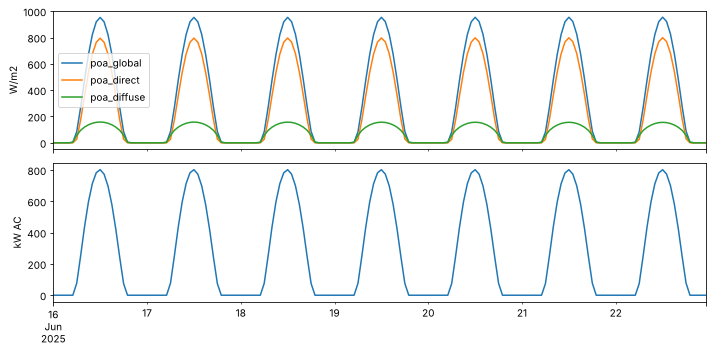

In [3]:
solpos = loc.get_solarposition(weather.index)
poa = pvlib.irradiance.get_total_irradiance(
    surface_tilt=25, surface_azimuth=180,
    solar_zenith=solpos.apparent_zenith, solar_azimuth=solpos.azimuth,
    dni=weather.dni, ghi=weather.ghi, dhi=weather.dhi)
temp_cell = pvlib.temperature.faiman(poa.poa_global, weather.temp_air, weather.wind_speed)
pdc = pvlib.pvsystem.pvwatts_dc(poa.poa_global, temp_cell, pdc0=1000, gamma_pdc=-0.004)   # kW
pac_by_hand = pvlib.inverter.pvwatts(pdc, pdc0=1000 / 0.96).clip(lower=0)

print(f"annual yield: {pac_by_hand.sum() / 1000:.0f} kWh per kWp")
print("hour of day with highest average output:", pac_by_hand.groupby(pac_by_hand.index.hour).mean().idxmax())

week = slice(f"{config.YEAR}-06-16", f"{config.YEAR}-06-22")
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 5))
poa.loc[week, ["poa_global", "poa_direct", "poa_diffuse"]].plot(ax=ax[0]); ax[0].set_ylabel("W/m2")
pac_by_hand.loc[week].plot(ax=ax[1]); ax[1].set_ylabel("kW AC")
plt.tight_layout()

Peak at noon local standard time, good, so the time zone is right. Real
Fresno numbers are usually somewhere around 1,700-2,000 kWh/kWp, so the
clear-sky number is the "no clouds ever" upper end, as expected.

## 3. Same thing with `ModelChain`
`ModelChain` wires all those steps together. Does it agree with my
by-hand version?

In [4]:
# first try: the simplest system I could think of
system = pvlib.pvsystem.PVSystem(surface_tilt=25, surface_azimuth=180,
                                 module_parameters={"pdc0": 1000, "gamma_pdc": -0.004},
                                 inverter_parameters={"pdc0": 1000 / 0.96})
try:
    pvlib.modelchain.ModelChain.with_pvwatts(system, loc).run_model(weather)
except ValueError as e:
    print("didn't work:", str(e)[:120], "...")

didn't work: Could not infer temperature model from ModelChain.system.  If Arrays are used to construct the PVSystem, check that all  ...


In [5]:
from pvlib.temperature import TEMPERATURE_MODEL_PARAMETERS

def make_system(tilt=25, azimuth=180):
    return pvlib.pvsystem.PVSystem(
        surface_tilt=tilt, surface_azimuth=azimuth,
        module_parameters={"pdc0": 1000, "gamma_pdc": -0.004},
        inverter_parameters={"pdc0": 1000 / 0.96},
        temperature_model_parameters=TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_polymer"])

mc = pvlib.modelchain.ModelChain.with_pvwatts(make_system(), loc)
mc.run_model(weather)
pac_mc = mc.results.ac.clip(lower=0)
print(f"ModelChain: {pac_mc.sum() / 1000:.0f} kWh/kWp   by hand: {pac_by_hand.sum() / 1000:.0f} kWh/kWp")

ModelChain: 1745 kWh/kWp   by hand: 2004 kWh/kWp


**They don't agree: ModelChain is ~13% lower.** My first guess was the
temperature model (Faiman by hand, SAPM in ModelChain), but that's small.
The real reason: `with_pvwatts` also applies PVWatts' default "system
losses" (soiling, wiring, mismatch, etc., about 14% in total). Turning
those off to check:

In [6]:
mc_noloss = pvlib.modelchain.ModelChain.with_pvwatts(make_system(), loc, losses_model="no_loss")
mc_noloss.run_model(weather)
print(f"ModelChain without system losses: {mc_noloss.results.ac.clip(lower=0).sum() / 1000:.0f} kWh/kWp")
print(mc_noloss)

ModelChain without system losses: 2033 kWh/kWp
ModelChain: 
  name: None
  clearsky_model: ineichen
  transposition_model: perez
  solar_position_method: nrel_numpy
  airmass_model: kastenyoung1989
  dc_model: pvwatts_dc
  ac_model: pvwatts_inverter
  aoi_model: physical_aoi_loss
  spectral_model: no_spectral_loss
  temperature_model: sapm_temp
  losses_model: no_extra_losses


Now it's within a couple of percent of my by-hand number. What's left is
the sky model (ModelChain uses Perez for diffuse light, by hand I used
the default isotropic one) and the temperature model.

I'm keeping the 14% losses from here on, since real systems have them.

Also **didn't work at first**: `ModelChain.with_pvwatts` needs
`temperature_model_parameters`, otherwise it errors out trying to guess
the temperature model (the try/except cell above).

## 4. Tilt and direction

CAISO prices are lowest midday (lots of solar on the grid) and highest
in the evening. So maybe a west-facing array is worth more even if it
makes fewer kWh?

In [7]:
rows = []
profiles = {}
for name, tilt, az in [("south 25°", 25, 180), ("south 10°", 10, 180), ("south 35°", 35, 180),
                       ("west 25°", 25, 270), ("east 25°", 25, 90), ("flat", 0, 180)]:
    mc = pvlib.modelchain.ModelChain.with_pvwatts(make_system(tilt, az), loc)
    mc.run_model(weather)
    ac = mc.results.ac.clip(lower=0)
    profiles[name] = ac
    rows.append({"layout": name, "kWh_per_kWp": ac.sum() / 1000,
                 "share_after_4pm": ac[ac.index.hour >= 16].sum() / ac.sum()})
pd.DataFrame(rows).round(2)

,layout,kWh_per_kWp,share_after_4pm
0,south 25°,1745.47,0.08
1,south 10°,1614.90,0.08
2,south 35°,1775.92,0.07
3,west 25°,1402.04,0.17
4,east 25°,1416.91,0.02
5,flat,1471.24,0.09


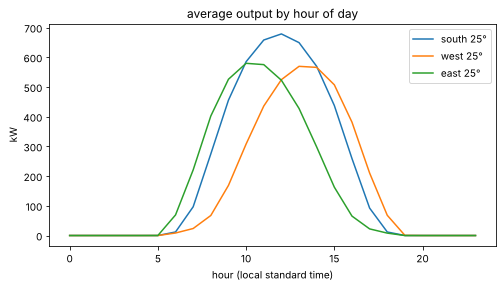

In [8]:
pd.DataFrame({k: v.groupby(v.index.hour).mean() for k, v in profiles.items()
              if k in ["south 25°", "west 25°", "east 25°"]}).plot(
    figsize=(8, 4), title="average output by hour of day")
plt.xlabel("hour (local standard time)"); plt.ylabel("kW");

West gives up some energy but moves more of it to after 4 pm. Whether
that's worth it depends on the price spread, which is a PyPSA question.
For a rooftop the tilt is usually set by the roof anyway (often close to
flat on industrial buildings).

## 5. Fixed vs single-axis tracking
Ground-mounted plants often track the sun east-west. Probably not on a
factory roof, but curious how much it adds.

In [9]:
tracker = pvlib.tracking.singleaxis(solpos.apparent_zenith, solpos.azimuth,
                                    axis_azimuth=180, max_angle=55, backtrack=True, gcr=0.35)
poa_trk = pvlib.irradiance.get_total_irradiance(
    surface_tilt=tracker.surface_tilt.fillna(0), surface_azimuth=tracker.surface_azimuth.fillna(180),
    solar_zenith=solpos.apparent_zenith, solar_azimuth=solpos.azimuth,
    dni=weather.dni, ghi=weather.ghi, dhi=weather.dhi)
tc_trk = pvlib.temperature.faiman(poa_trk.poa_global, weather.temp_air, weather.wind_speed)
ac_trk = pvlib.inverter.pvwatts(pvlib.pvsystem.pvwatts_dc(poa_trk.poa_global, tc_trk, 1000, -0.004),
                                pdc0=1000 / 0.96).clip(lower=0)
print(f"tracking: {ac_trk.sum() / 1000:.0f} kWh/kWp vs fixed south 25°: {pac_by_hand.sum() / 1000:.0f}")

tracking: 2278 kWh/kWp vs fixed south 25°: 2004


**Gotcha:** the tracker returns NaN angles at night, and NaN poisons the
sum. I filled them with flat/south. Easy to miss, the total just comes out
smaller than it should.

## 6. How much does heat cost?
Compare what the array makes vs what it would make at 25 °C cell temperature.

max cell temperature: 58 °C


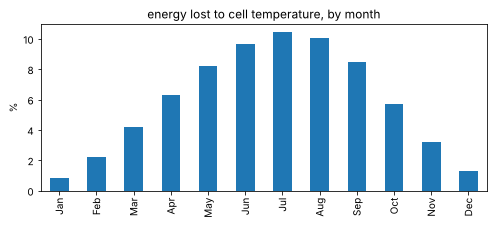

In [10]:
pdc_hot = pvlib.pvsystem.pvwatts_dc(poa.poa_global, temp_cell, 1000, -0.004)
pdc_25 = pvlib.pvsystem.pvwatts_dc(poa.poa_global, 25.0, 1000, -0.004)
loss = 1 - pdc_hot.resample("ME").sum() / pdc_25.resample("ME").sum()
loss.index = loss.index.strftime("%b")
ax = (100 * loss).plot.bar(figsize=(8, 3), title="energy lost to cell temperature, by month")
ax.set_ylabel("%");
print("max cell temperature:", round(temp_cell.max()), "°C")

With the made-up temperatures this is only a rough idea, but the summer
loss is real and Fresno summers are hot. Worth re-running with NSRDB.

## Save for the other notebooks
PV output per kWp (so PyPSA can scale it) plus the outdoor temperature
(the heat pump COP depends on it).

In [11]:
out = pd.DataFrame({
    "pv_kw_per_kwp": profiles["south 25°"] / 1000,
    "temp_air": weather.temp_air,
})
# drop the time zone so it lines up with the loadcast index (also local, no DST)
out.index = out.index.tz_localize(None)
out.index.name = "time"
out.to_csv(config.DATA_DIR / "pv_and_weather.csv")
print("saved", config.DATA_DIR / "pv_and_weather.csv", "| weather:", weather_source)
out.describe().round(2)

saved /home/user/energy_dt_ml/notebooks/../data/pv_and_weather.csv | weather: clear-sky + made-up temperature (NOT real weather)


,pv_kw_per_kwp,temp_air
count,8760.00,8760.00
mean,0.20,18.00
std,0.26,8.63
min,0.00,1.00
25%,0.00,11.63
50%,0.00,18.01
75%,0.46,24.37
max,0.75,35.00
